# ¿Ayuda más ReAct con conocimiento chileno, poco conocido y modelos chicos?

**Proyecto final CC5219 — IA multimodal, Universidad de Chile.**

Informe del proyecto. El ejecutable es `experimento.ipynb` (Colab, GPU T4): corre el experimento y genera la figura y las cifras de este informe.

## A. Informe

### 1. Pregunta y diseño

¿La ventaja de ReAct (Yao et al., 2022) sobre responder de memoria crece cuando el conocimiento es **local** (Chile), **poco conocido**, o cuando el **modelo es pequeño**?

Para separar "local" de "poco conocido", el diseño es 2×2: **origen** (chile / no_chile) × **popularidad** (pocos / muchos idiomas en Wikipedia).

Para el tamaño hay dos predicciones opuestas:
- **Conocimiento** (Mallen et al., 2023; Kandpal et al., 2023): el modelo chico sabe menos, así que gana más al buscar.
- **Capacidad** (Figura 3 de ReAct): operar la herramienta exige un modelo capaz, así que el chico gana menos.

La pregunta, las condiciones, la métrica y el split se fijaron antes de correr los modelos. Los prompts se congelaron con dev, y el test no se usó para ajustar nada.

### 2. Dataset

**Por qué uno nuevo:** PopQA mide popularidad, pero con un salto y en inglés; HotpotQA es multi-hop, pero en inglés. Ninguno cruza origen × popularidad emparejada con preguntas multi-hop en español que se puedan responder con Wikipedia.

- **Fuente y licencia:** Wikipedia en español, **CC BY-SA 4.0**. El dataset derivado usa la misma licencia.
- **Construcción:** preguntas **puente**, como en HotpotQA.
  - Se toma un artículo A, de Chile o de 8 países de control, y un artículo B enlazado en su intro.
  - La pregunta describe a B con datos de A, y la respuesta sale de B.
  - La popularidad es el número de idiomas de A (≤ 10 / ≥ 21), y el control se empareja por tramos con Chile.
  - Claude generó las preguntas; las filtraron reglas automáticas y una verificación adversarial con otro LLM.
- **Tamaño:** 230 preguntas válidas, de 400 pares. Split fijo: dev 20 y **test 160** (40 por celda). La auditoría manual de 20 preguntas encontró 1 mala y 1 dudosa.

### 3. Modelos, baseline y métrica

- **Modelos:** Qwen2.5-Instruct **1.5B, 3B y 7B**, en AWQ de 4 bits, con vLLM, greedy y contexto de 8192 tokens.
- **Extra: 14B**, con otra configuración: sin RAG y contexto de 6144 tokens (lo que cabe en la T4).
- **Condiciones** (mismo few-shot de 2 ejemplos):
  - **Directa** (baseline): responde de memoria.
  - **RAG fijo** (baseline de recuperación): una búsqueda con la pregunta y 3 resultados.
  - **ReAct:** hasta 7 pasos, con `Buscar[título]` (devuelve la intro, o 5 títulos similares si no existe) y `Terminar[respuesta]`.
- **Métrica:** Exact Match (principal) y F1, normalizados y con alias. Los IC 95 % son por bootstrap; la ganancia usa bootstrap pareado.

### 4. Resultados (test, n = 160)

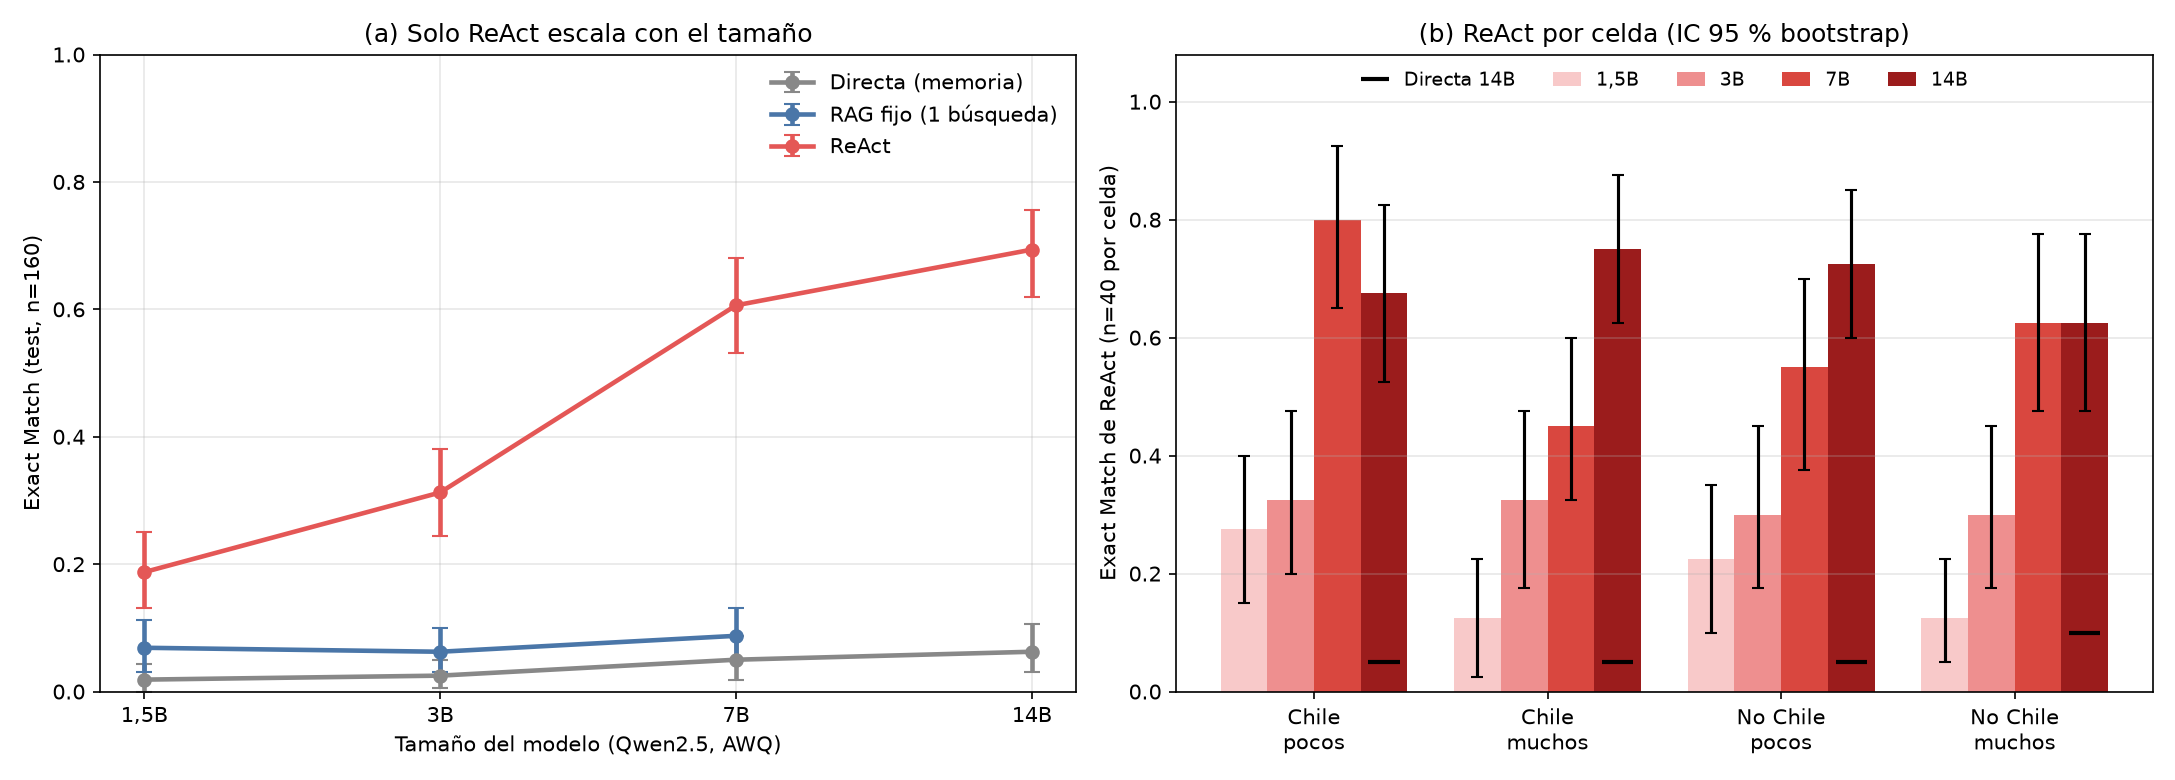

| EM [IC 95 %] (F1) | Directa | RAG fijo | ReAct | Ganancia ReAct − Directa |
|---|---|---|---|---|
| 1,5B | 0,02 [0,00–0,04] (0,12) | 0,07 [0,03–0,11] (0,14) | **0,19** [0,13–0,25] (0,21) | 0,17 [0,11–0,24] |
| 3B   | 0,03 [0,01–0,05] (0,08) | 0,06 [0,03–0,10] (0,13) | **0,31** [0,24–0,38] (0,38) | 0,29 [0,22–0,36] |
| 7B   | 0,05 [0,02–0,09] (0,12) | 0,09 [0,05–0,13] (0,15) | **0,61** [0,53–0,68] (0,67) | 0,56 [0,47–0,63] |
| 14B (extra) | 0,06 [0,03–0,11] (0,16) | — | **0,69** [0,62–0,76] (0,73) | 0,63 [0,54–0,70] |

| Ganancia por grupo | Chile | No Chile | Pocos idiomas | Muchos idiomas |
|---|---|---|---|---|
| 1,5B | 0,19 | 0,15 | 0,23 | 0,11 |
| 3B   | 0,31 | 0,26 | 0,28 | 0,30 |
| 7B   | 0,59 [0,46–0,70] | 0,53 [0,41–0,64] | 0,64 [0,53–0,75] | 0,47 [0,35–0,59] |
| 14B  | 0,66 [0,56–0,76] | 0,60 [0,47–0,71] | 0,65 [0,55–0,76] | 0,61 [0,47–0,72] |

1. **Memoria en el piso:** Directa acierta ≤ 10 % en todas las celdas, incluso con el 14B.
2. **La ganancia crece con el tamaño** (0,17 → 0,29 → 0,56), y los IC de 1,5B y 7B no se tocan. Con el 14B (0,63), la curva se aplana.
3. **Efecto local no detectable:** Chile saca +4, +5, +6 y +6 puntos sobre no Chile (de 1,5B a 14B), pero los IC se superponen.
4. **Popularidad confundida con el tipo de pregunta:** ReAct 7B rinde 0,80 en chile_pocos y 0,45 en chile_muchos.
   - En "pocos" abundan las preguntas fáciles de "ciudad natal"; dentro de ese tipo, la brecha casi desaparece (0,83 vs. 0,78).
   - Con el 14B, la brecha desaparece (0,68 vs. 0,75).
5. **ReAct supera a RAG fijo** (7B: +0,52): una búsqueda con la pregunta casi nunca trae a A.

### 5. Análisis de errores

- **Fallos de ReAct:** 130 / 110 / 63 / 49 (1,5B → 14B). En el 1,5B dominan los bucles (66 llegan a 7 pasos); desde el 3B, no llegar a la página de A o B.
- **Herramienta:** `Buscar` exige el título exacto, y el 42–65 % de las búsquedas falla. Tras un fallo, el paso siguiente usa una de las 5 sugerencias solo el **7 / 15 / 21 / 23 %** de las veces. B estaba entre las sugerencias 80 veces con el 7B (lo buscó 17) y 65 con el 14B (lo buscó 10).
- **Alucinaciones:** el paper de ReAct reporta 0 % entre los fallos de ReAct (Tabla 2: PaLM-540B, revisión manual). Aquí son el **11 / 25 / 35 / 16 %** de los fallos.
  - Criterio: respuesta concreta (no vacía, no abstención, no acierto parcial) que no aparece en nada de lo que el modelo leyó. Es una cota aproximada.
  - Ocurren sobre todo tras búsquedas fallidas: el modelo rellena ("Ñuñoa Sur" en vez de Macul).
  - El 11 % del 1,5B engaña, porque más de la mitad de sus fallos son bucles sin respuesta.

**Errores concretos:**

1. **Bucle** (1,5B, ReAct, `chile_pocos_040`): busca 7 veces "Coalición de izquierda que gobernó Chile en 1971". *Hipótesis:* no sabe el nombre (Unidad Popular) y el modelo chico no cambia de estrategia.
2. **Reformula sin usar las sugerencias** (14B, ReAct, `chile_pocos_059`): "San Javier, Chile" falla y la primera sugerencia es B ("San Javier de Loncomilla"). No la busca y reformula ("Fundación de San Javier, Chile"…) hasta agotar los pasos. *Hipótesis:* usa `Buscar` como un buscador por palabras clave.
3. **Identifica B, pero falla el título** (7B, ReAct, `chile_muchos_019`): saca Taltal de "Cerro Paranal", busca "Taltal, Chile" (no existe) y responde "Sierra Gorda". *Hipótesis:* razonamiento correcto, falla la interfaz y el modelo rellena.
4. **Responde el puente** (7B, ReAct, `chile_muchos_046`): responde "San Pedro de Atacama" (el poblado), no la provincia (El Loa). Se clasifica como `no_encontro_B`: nunca abre la página del poblado. *Hipótesis:* pierde de vista qué pedía la pregunta.
5. **RAG con ruido** (7B, RAG, `chile_pocos_011`): la pregunta es sobre el campo de prisioneros de Chacabuco (1973). La búsqueda trae a San Martín, Carrera y O'Higgins, y responde "Santiago de Chile" (la respuesta es Valparaíso). *Hipótesis:* el buscador por palabras clave asocia "Chacabuco" con la batalla de 1817, y B no está en la pregunta.
6. **EM estricto** (7B, ReAct, `no_chile_pocos_048`): "río Ródano y Saona" frente a "Ródano y Saona". *Hipótesis:* error de la métrica, no del modelo; F1 lo recoge.
7. **Respuesta por defecto** (1,5B, Directa): "Santiago" en 9 preguntas chilenas. *Hipótesis:* sin conocimiento, devuelve la entidad más frecuente del contexto.

### 6. Conclusiones

1. En preguntas de dos saltos, la memoria no alcanza con ningún tamaño. ReAct sube el EM a 0,19 / 0,31 / 0,61 / 0,69.
2. **La ventaja de ReAct crece con el tamaño:** domina la capacidad de operar la herramienta, no el conocimiento. Es consistente con la Figura 3 de ReAct, aunque allí se compara con CoT.
3. **No hay evidencia de un efecto local ni de popularidad sobre la ganancia.** La ventaja de Chile (+4 a +6 puntos) no es significativa, y la brecha por popularidad se explica por el tipo de pregunta.
4. **El cuello de botella restante es la interfaz con la herramienta:** títulos exactos y sugerencias ignoradas. Cuando la búsqueda falla, el modelo a veces rellena con una respuesta inventada, algo que el paper no observó con PaLM-540B.

### 7. Limitaciones

- **Tamaño:** 40 preguntas por celda (IC ≈ ±15 puntos), sin potencia para el efecto local ni para la interacción.
- **Dataset:** generado y verificado por un LLM; se estima un 5–10 % de preguntas malas.
- **Semillas asimétricas:** profundidad de subcategorías 2 en Chile y 1 en el control, y Perú es el 62 % del control en "pocos".
- **Alcance:** solo Qwen2.5 cuantizado y un prompt fijo, sin CoT ni Act. El 14B tiene otra configuración. El EM es estricto (error 6). La medida de alucinación es automática y aproximada.

### 8. Cómputo, reproducibilidad y uso de IA

- **Cómputo:** Colab con GPU **T4**.
  - Test de 1,5B, 3B y 7B: menos de 1 h en total.
  - 14B: ~30 min.
  - Dataset: ~45 min de llamadas a la API, sin GPU.
- **Versiones:** Python 3.13, **vllm 0.34.0**, **torch 2.14.0+cu130** (AWQ, `dtype="half"`).
- **Semillas:** `SEMILLA = 0` en pares y split; vLLM `seed=0` con `temperature=0`; bootstrap con `random.Random(0)`.
- **Caché y trazas:** todas las consultas a Wikipedia quedan en una caché en disco, y cada corrida guarda trazas completas (prompt, pasos, respuesta) en JSONL.
- **Uso de IA:**
  - **Código:** escrito con **Claude Code**, a partir de especificaciones previas. El diseño, la revisión y las pruebas son del autor.
  - **Dataset:** **Claude** generó las preguntas y otras sesiones de Claude, sin ese contexto, las verificaron, y se guardaron sus prompts y salidas.
  - **Informe:** redactado con ayuda de Claude Code; las cifras salen de `experimento.ipynb`.

**Referencias:**
- Yao et al. (2022), *ReAct*.
- Mallen et al. (2023), *When Not to Trust Language Models* (PopQA).
- Kandpal et al. (2023), *LLMs Struggle to Learn Long-Tail Knowledge*.
- Yang et al. (2018), *HotpotQA*.